## csv文件转换成临时表

In [1]:

import pandas as pd
from pyspark.sql import SparkSession, Row
from decimal import Decimal
from pyspark.sql.types import StructType, StringType, StructField, IntegerType, DecimalType, ByteType

spark = SparkSession.builder \
    .appName("zip_csv_demo") \
    .master("local[2]") \
    .getOrCreate()
sc = spark.sparkContext

In [2]:
#1.textfile加载csv
RawZipRDD = sc.textFile("../data/Zipssortedbycitystate.csv")

In [3]:
#rdd->ROW
#过滤表头，按逗号分割，组装Row对象
zipRDD = RawZipRDD \
    .filter(lambda line: not line.startswith("CITY,STATE,POSTALCODE")) \
    .map(lambda line: line.split(","))

zipRows = zipRDD.map(lambda p: Row(
    CITY=p[0].strip(),
    STATE=p[1].strip(),
    POSTALCODE=p[2].strip()
))

In [4]:
# RDD -> DataFrame：城市、州和邮编均按文本保存。
# 邮编若存在前导 0，使用数值类型会导致信息丢失。
schema = StructType([
    StructField("CITY", StringType(), nullable=False),
    StructField("STATE", StringType(), nullable=False),
    StructField("POSTALCODE", StringType(), nullable=False),
])
df = spark.createDataFrame(zipRows, schema=schema)

In [5]:
# 注册临时视图 ziptable（替代已弃用的 registerTempTable）
df.createOrReplaceTempView("ziptable")

In [6]:
#查看表结构
df.printSchema()
df.show(10)


root
 |-- CITY: string (nullable = false)
 |-- STATE: string (nullable = false)
 |-- POSTALCODE: string (nullable = false)

+-----------+-----+----------+
|       CITY|STATE|POSTALCODE|
+-----------+-----+----------+
|  ABBEVILLE|   AL|     36310|
|  ABBEVILLE|   LA|     70510|
|  ABBEVILLE|   MS|     38601|
|      ABBOT|   ME|      4406|
|     ABBOTT|   TX|     76621|
|  ABBYVILLE|   KS|     67510|
|ABERCROMBIE|   ND|     58001|
|   ABERDEEN|   KY|     42201|
|   ABERDEEN|   MS|     39730|
|   ABERDEEN|   OH|     45101|
+-----------+-----+----------+
only showing top 10 rows



In [7]:

#示例查询
print("==== 查询STATE=AL的数据 ====")
df.filter("STATE = 'AL'").show()
spark.sql("select * from ziptable where STATE = 'AL'").show()

==== 查询STATE=AL的数据 ====
+--------------+-----+----------+
|          CITY|STATE|POSTALCODE|
+--------------+-----+----------+
|     ABBEVILLE|   AL|     36310|
|         ADGER|   AL|     35006|
|       ALBERTA|   AL|     36720|
|   ALBERTVILLE|   AL|     35950|
|ALEXANDER CITY|   AL|     35011|
|          ALMA|   AL|     36501|
|        ALPINE|   AL|     35014|
|         ALTON|   AL|     35015|
|     ANDALUSIA|   AL|     36420|
|     ANNEMANIE|   AL|     36721|
|      ANNISTON|   AL|     36202|
|      ANNISTON|   AL|     36205|
|      ANNISTON|   AL|     36207|
|       ARDMORE|   AL|     35739|
|        ARITON|   AL|     36311|
|     ARLINGTON|   AL|     36722|
|        ATHENS|   AL|     35611|
|        ATHENS|   AL|     35613|
|        ATMORE|   AL|     36502|
|        ATMORE|   AL|     36504|
+--------------+-----+----------+
only showing top 20 rows

+--------------+-----+----------+
|          CITY|STATE|POSTALCODE|
+--------------+-----+----------+
|     ABBEVILLE|   AL|     36310

In [8]:
# 加载销售数据，并准备与邮编表连接
sale_df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .option("quote", '"')
    .option("escape", '"')
    .csv("../data/sales_data.csv")
)

# 复用前面生成的邮编 DataFrame，并提供 SQL 查询使用的别名
ZIP_df = df
ZIP_df.createOrReplaceTempView("zip_table")
sale_df.createOrReplaceTempView("sale_table")

sale_df.printSchema()
sale_df.show(5)

root
 |-- ORDERNUMBER: integer (nullable = true)
 |-- QUANTITYORDERED: integer (nullable = true)
 |-- PRICEEACH: double (nullable = true)
 |-- ORDERLINENUMBER: integer (nullable = true)
 |-- SALES: double (nullable = true)
 |-- ORDERDATE: string (nullable = true)
 |-- STATUS: string (nullable = true)
 |-- QTR_ID: integer (nullable = true)
 |-- MONTH_ID: integer (nullable = true)
 |-- YEAR_ID: integer (nullable = true)
 |-- PRODUCTLINE: string (nullable = true)
 |-- MSRP: integer (nullable = true)
 |-- PRODUCTCODE: string (nullable = true)
 |-- CUSTOMERNAME: string (nullable = true)
 |-- PHONE: string (nullable = true)
 |-- ADDRESSLINE1: string (nullable = true)
 |-- ADDRESSLINE2: string (nullable = true)
 |-- CITY: string (nullable = true)
 |-- STATE: string (nullable = true)
 |-- POSTALCODE: integer (nullable = true)
 |-- COUNTRY: string (nullable = true)
 |-- TERRITORY: string (nullable = true)
 |-- CONTACTLASTNAME: string (nullable = true)
 |-- CONTACTFIRSTNAME: string (nullable = t

In [9]:
# 按城市左连接销售数据和邮编数据
joined_df = sale_df.join(
    ZIP_df,
    sale_df.CITY == ZIP_df.CITY,
    "left_outer"
)
joined_df.filter("ORDERNUMBER = 10159").distinct().show()

+-----------+---------------+---------+---------------+-------+---------------+-------+------+--------+-------+-----------+----+-----------+--------------------+----------+---------------+------------+-------------+-----+----------+-------+---------+---------------+----------------+-------------+-----+----------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|      ORDERDATE| STATUS|QTR_ID|MONTH_ID|YEAR_ID|PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|     PHONE|   ADDRESSLINE1|ADDRESSLINE2|         CITY|STATE|POSTALCODE|COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|         CITY|STATE|POSTALCODE|
+-----------+---------------+---------+---------------+-------+---------------+-------+------+--------+-------+-----------+----+-----------+--------------------+----------+---------------+------------+-------------+-----+----------+-------+---------+---------------+----------------+-------------+-----+----------+
|      10159|             49|    100.0|             14|

In [10]:
# SQL 连接查询：为右表邮编列设置别名，避免与销售表 POSTALCODE 重名
spark.sql("""
    SELECT s.*, z.POSTALCODE AS ZIP_POSTALCODE
    FROM sale_table s
    LEFT JOIN zip_table z
      ON s.CITY = z.CITY
    WHERE s.ORDERNUMBER = 10159
""").show()

+-----------+---------------+---------+---------------+-------+---------------+-------+------+--------+-------+-----------+----+-----------+--------------------+----------+---------------+------------+-------------+-----+----------+-------+---------+---------------+----------------+--------------+
|ORDERNUMBER|QUANTITYORDERED|PRICEEACH|ORDERLINENUMBER|  SALES|      ORDERDATE| STATUS|QTR_ID|MONTH_ID|YEAR_ID|PRODUCTLINE|MSRP|PRODUCTCODE|        CUSTOMERNAME|     PHONE|   ADDRESSLINE1|ADDRESSLINE2|         CITY|STATE|POSTALCODE|COUNTRY|TERRITORY|CONTACTLASTNAME|CONTACTFIRSTNAME|ZIP_POSTALCODE|
+-----------+---------------+---------+---------------+-------+---------------+-------+------+--------+-------+-----------+----+-----------+--------------------+----------+---------------+------------+-------------+-----+----------+-------+---------+---------------+----------------+--------------+
|      10159|             49|    100.0|             14|5205.27|10/10/2003 0:00|Shipped|     4|      10|

In [11]:
import pandas as pd

people_data = [['Alex', 10], ['Bob', 12], ['Clarke', 13]]
people_df = pd.DataFrame(people_data, columns=['Name', 'Age'])
print(people_df)
print(people_df.loc[1])
print(people_df.iloc[0])
# 将 Name 设为索引；使用 people_df，避免覆盖上面的 Spark DataFrame df
people_df.set_index('Name', inplace=True)
print(people_df)

     Name  Age
0    Alex   10
1     Bob   12
2  Clarke   13
Name    Bob
Age      12
Name: 1, dtype: object
Name    Alex
Age       10
Name: 0, dtype: object
        Age
Name       
Alex     10
Bob      12
Clarke   13


In [12]:
# 按州统计订单数；请先按顺序运行前面的销售数据加载单元
GroupByState_df = sale_df.groupBy('STATE').count().orderBy('STATE')
GroupByState_pandas_df = GroupByState_df.toPandas().set_index('STATE')
print(GroupByState_pandas_df)

       count
STATE       
None       2
CA         2
NY         1


Text(0, 0.5, 'Order count')

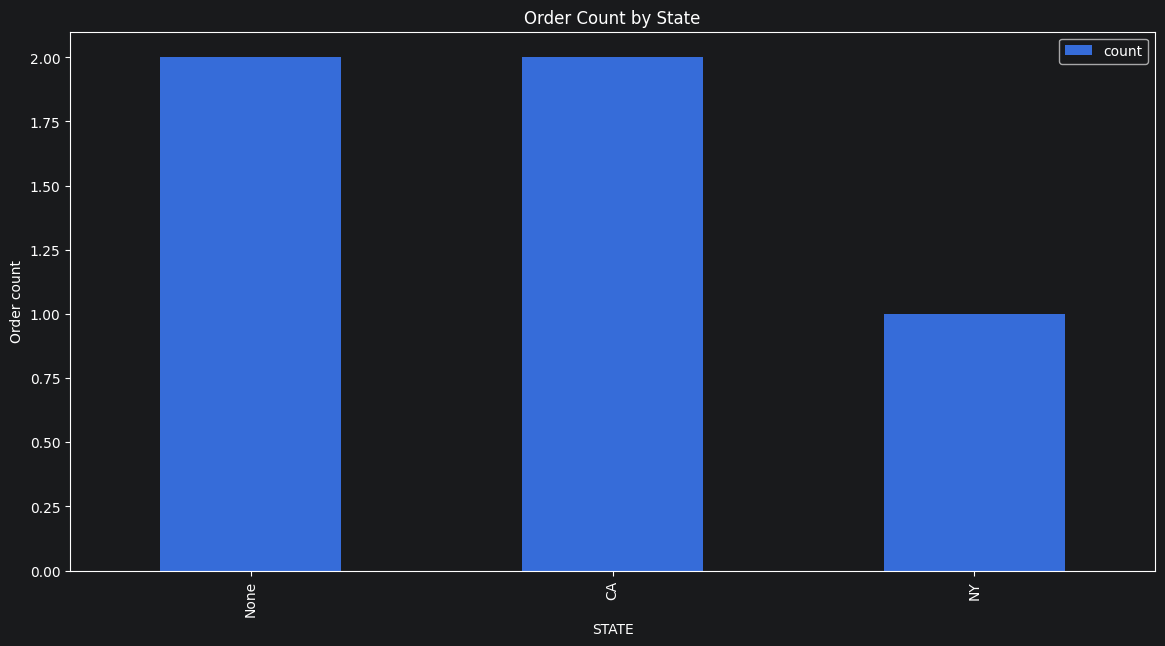

In [13]:
import matplotlib.pyplot as plt

ax = GroupByState_pandas_df['count'].plot(
    kind='bar',
    title='Order Count by State',
    figsize=(14, 7),
    legend=True,
    fontsize=10,
)
ax.set_xlabel('STATE')
ax.set_ylabel('Order count')

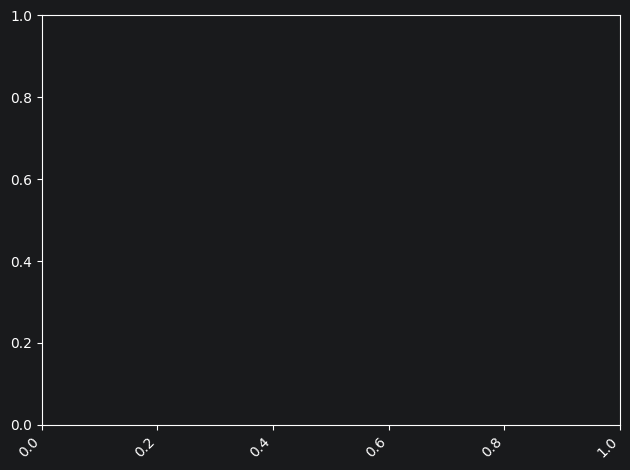

In [14]:
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()